# 03 · EDA y visualizaciones corregidas
**EP5 · hallazgos verificables, etiquetas legibles y comparaciones justas**

Se generan figuras en `images/`. Se usa el **mismo CSV publicado a Looker**, evitando cifras distintas entre informe y dashboard. Las figuras se guardan solo cuando se ejecuta este notebook.

**Advertencia de interpretación:** datos de catálogo muestreado, sin información de consumo, retención o espectadores.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src' / 'pipeline.py').exists() else Path.cwd().parent
assert (ROOT / 'src' / 'pipeline.py').exists(), 'Ejecuta Jupyter desde la raíz del proyecto o notebooks/'
sys.path.insert(0,str(ROOT))
import pandas as pd, numpy as np
from IPython.display import display
from src.pipeline import load_sources, clean, audit, kpis, looker_table, OUT
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import spearmanr
D=pd.read_csv(OUT,encoding='utf-8-sig') if OUT.exists() else looker_table(clean(load_sources()))
IMAGES=ROOT/'images'; IMAGES.mkdir(exist_ok=True)
COLORS={'Movie':'#3366CC','TV Show':'#E68A2E'}
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':180,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
def savefig(name):
 plt.tight_layout();plt.savefig(IMAGES/name,bbox_inches='tight');plt.show()
print(f'Títulos={len(D):,} | Nota >=50 votos n={D.nota_confiable_50.notna().sum():,} | Finanzas n={D.finanzas_validas.sum():,}')

Títulos=31,991 | Nota >=50 votos n=15,397 | Finanzas n=3,492


## Figura 1 · Drama es el género principal más frecuente
**Pregunta:** ¿qué géneros principales predominan? **Tipo:** barras horizontales comparativas, porque el objetivo es comparar magnitudes. Se excluyen títulos sin género identificado de este ranking (sin eliminarlos de otros indicadores).

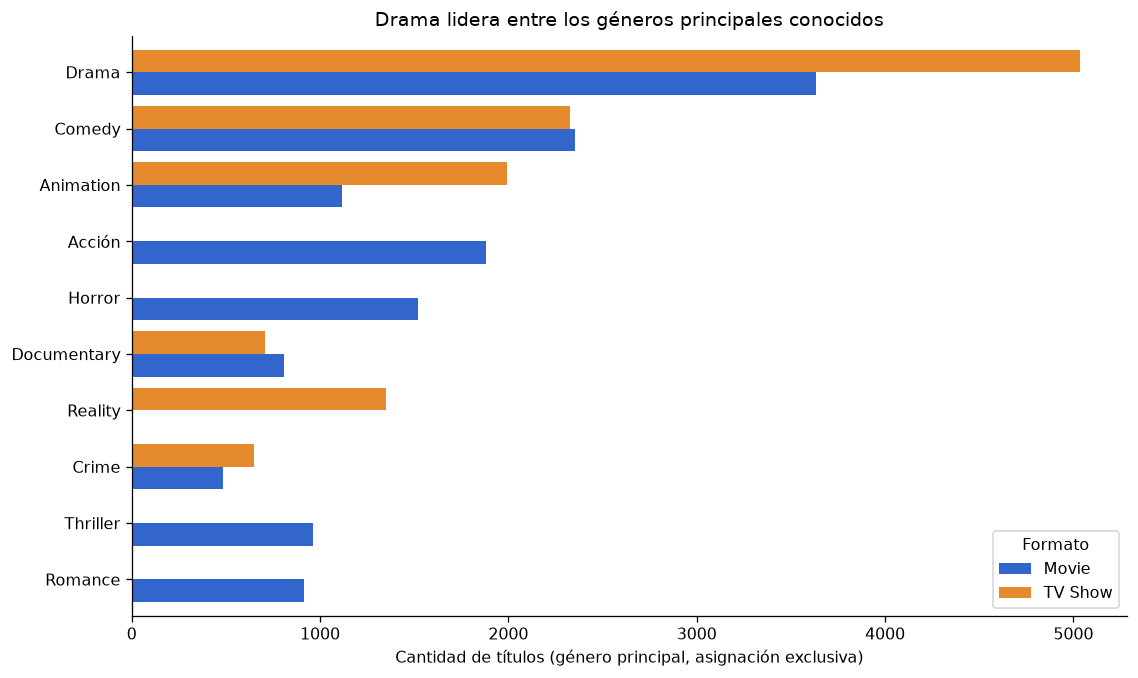

In [2]:
top=D.genero_principal.value_counts().head(10).index
mat=D[D.genero_principal.isin(top)].groupby(['genero_principal','type']).size().unstack(fill_value=0).reindex(top).iloc[::-1]
ax=mat.plot.barh(figsize=(10,6),color=[COLORS.get(x) for x in mat.columns],width=.8)
ax.set(xlabel='Cantidad de títulos (género principal, asignación exclusiva)',ylabel='',title='Drama lidera entre los géneros principales conocidos')
ax.legend(title='Formato');savefig('01_generos_principales.png')

## Figura 2 · La ausencia de directores es mayor en series
**Pregunta:** ¿con qué cobertura contamos para comparar talento? En series, el campo director tiene ausencias estructuralmente altas; el total de directores conocidos no es directamente comparable.

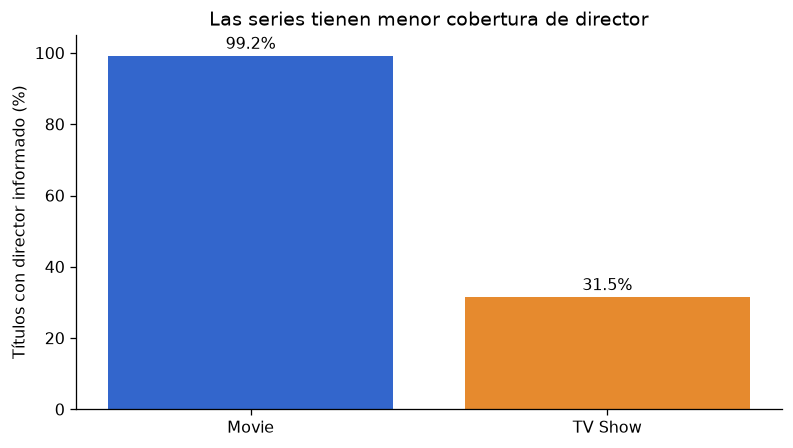

In [3]:
coverage=D.groupby('type').director_principal.apply(lambda s:100*s.notna().mean()).reindex(['Movie','TV Show'])
fig,ax=plt.subplots(figsize=(7,4)); bars=ax.bar(coverage.index,coverage.values,color=[COLORS[x] for x in coverage.index]);ax.set(ylabel='Títulos con director informado (%)',ylim=(0,105),title='Las series tienen menor cobertura de director')
for b,v in zip(bars,coverage):ax.text(b.get_x()+b.get_width()/2,v+2,f'{v:.1f}%',ha='center')
savefig('02_cobertura_directores.png')

## Figura 3 · Las series con >=50 votos tienen nota media superior
**Pregunta:** ¿cambia la comparación de calificaciones al exigir evidencia mínima? Barras por formato; no inferir lealtad ni retención de estas valoraciones.

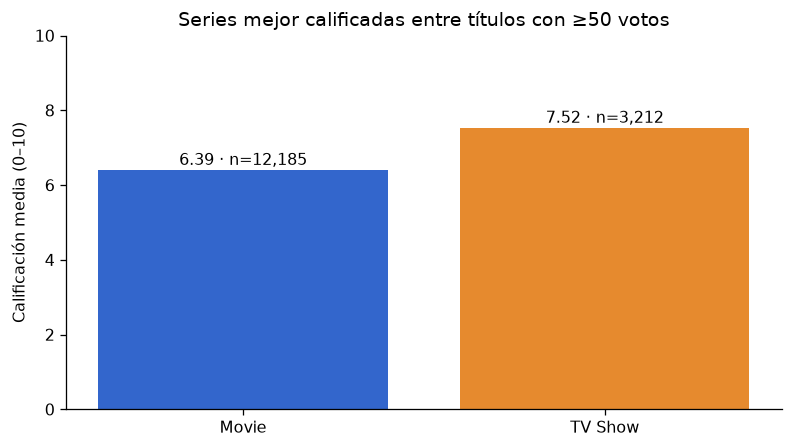

In [4]:
cal=D.groupby('type').agg(media=('nota_confiable_50','mean'),n=('nota_confiable_50','count')).reindex(['Movie','TV Show'])
fig,ax=plt.subplots(figsize=(7,4));bars=ax.bar(cal.index,cal.media,color=[COLORS[x] for x in cal.index]);ax.set(ylim=(0,10),ylabel='Calificación media (0–10)',title='Series mejor calificadas entre títulos con ≥50 votos')
for b,row in zip(bars,cal.itertuples()):ax.text(b.get_x()+b.get_width()/2,row.media+.15,f'{row.media:.2f} · n={row.n:,}',ha='center')
savefig('03_notas_50_votos.png')

## Figura 4 · Popularidad y nota tienen asociación, no independencia
**Pregunta:** ¿cómo se relacionan dentro de cada formato? Spearman por tipo, **nota >=50 votos**, eje de popularidad logarítmico; no mezclar escalas de formatos en un mismo promedio.

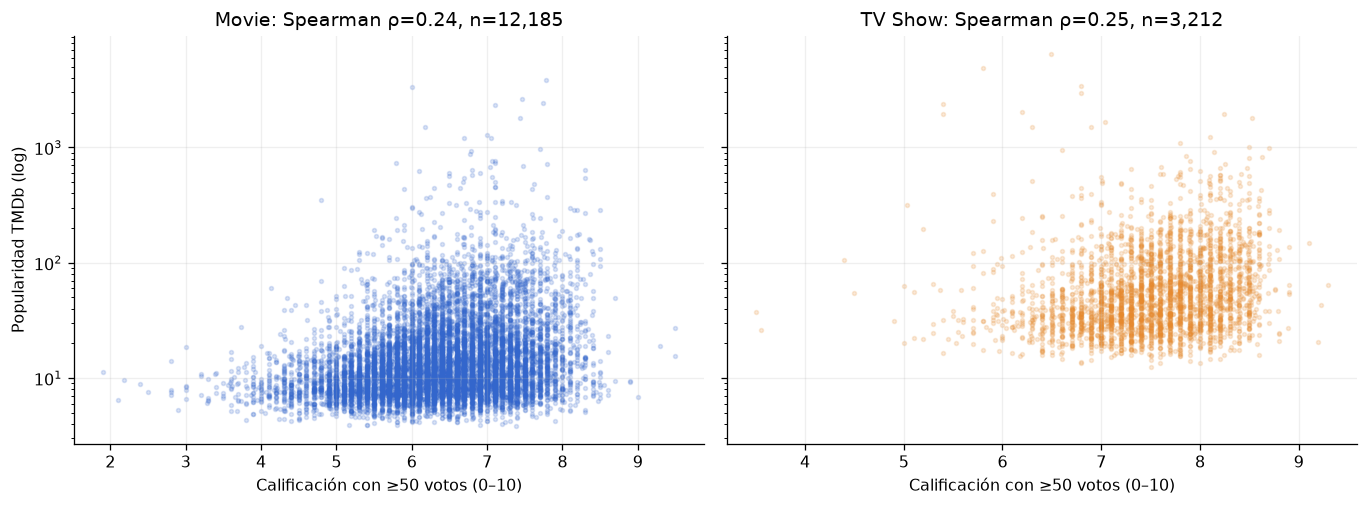

In [5]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,t in zip(axs,['Movie','TV Show']):
 s=D[(D.type==t)&D.nota_confiable_50.notna()&D.popularity.gt(0)]
 rho,p=spearmanr(s.popularity,s.nota_confiable_50)
 ax.scatter(s.nota_confiable_50,s.popularity,s=6,alpha=.18,color=COLORS[t],rasterized=True)
 ax.set(yscale='log',xlabel='Calificación con ≥50 votos (0–10)',title=f'{t}: Spearman ρ={rho:.2f}, n={len(s):,}')
 ax.grid(alpha=.2)
axs[0].set_ylabel('Popularidad TMDb (log)');savefig('04_popularidad_vs_nota.png')

## Figura 5 · Aproximadamente 64% de películas recupera el presupuesto
**Pregunta:** ¿cuántas películas de la submuestra financiera recuperan su inversión de producción? No representa rentabilidad neta de una plataforma de streaming.

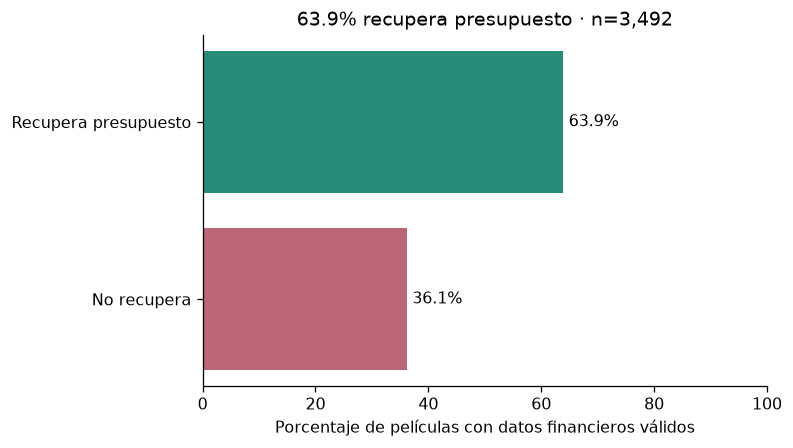

In [6]:
fin=D[D.finanzas_validas].copy();pct=100*fin.recupera_presupuesto.mean()
fig,ax=plt.subplots(figsize=(7,4));ax.barh(['Recupera presupuesto','No recupera'],[pct,100-pct],color=['#278C78','#BB6677']);ax.set(xlim=(0,100),xlabel='Porcentaje de películas con datos financieros válidos',title=f'{pct:.1f}% recupera presupuesto · n={len(fin):,}')
for i,v in enumerate([pct,100-pct]):ax.text(v+1,i,f'{v:.1f}%',va='center')
ax.invert_yaxis();savefig('05_recuperacion_presupuesto.png')

## Figura 6 · El tramo de mayor presupuesto lidera la mediana de ingresos/presupuesto
**Pregunta:** ¿qué segmentos muestran los mayores múltiplos medianos? Mostrar n; **no** equiparar múltiplo histórico con riesgo esperado o rendimiento de licencias.

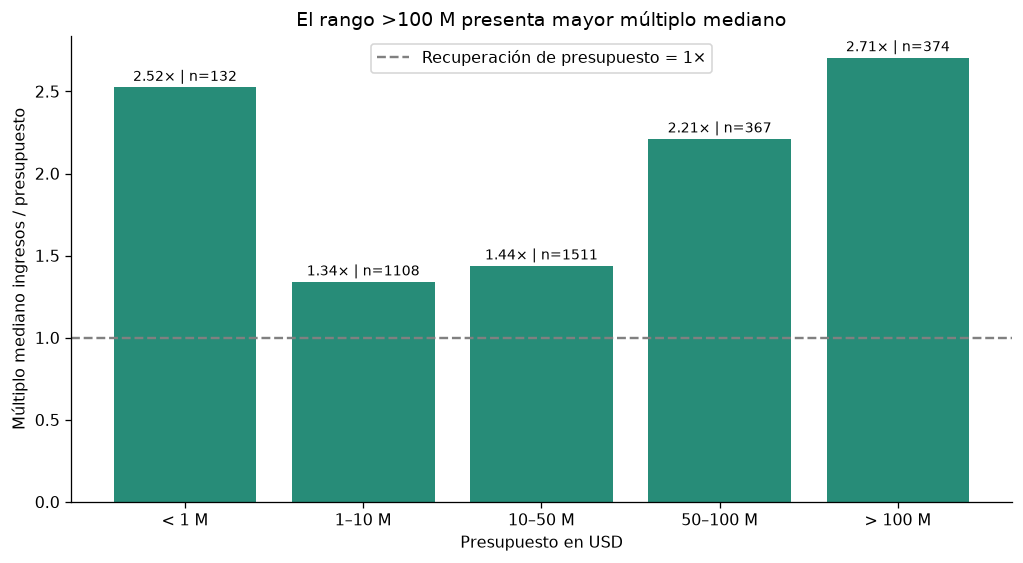

In [7]:
group=fin.groupby('rango_presupuesto',observed=True).agg(mediana=('multiplo_ingresos','median'),n=('content_key','size'),recupera=('recupera_presupuesto','mean'))
order=['< 1 M','1–10 M','10–50 M','50–100 M','> 100 M'];group=group.reindex(order)
fig,ax=plt.subplots(figsize=(9,5));bars=ax.bar(group.index,group.mediana,color='#278C78');ax.axhline(1,color='gray',linestyle='--',label='Recuperación de presupuesto = 1×')
for b,row in zip(bars,group.itertuples()):ax.text(b.get_x()+b.get_width()/2,row.mediana+.04,f'{row.mediana:.2f}× | n={row.n}',ha='center',fontsize=9)
ax.set(ylabel='Múltiplo mediano ingresos / presupuesto',xlabel='Presupuesto en USD',title='El rango >100 M presenta mayor múltiplo mediano');ax.legend();savefig('06_multiplo_por_presupuesto.png')

## 7. Tabla de control para el relato
Esta tabla resume las magnitudes verificables que deben coincidir en Looker, informe, infografía y presentación.

In [8]:
print('CONTROLES')
print('Películas con 50 votos:',cal.loc['Movie','n'],'series:',cal.loc['TV Show','n'])
print('Notas medias:',cal.media.round(3).to_dict())
print('Finanzas n:',len(fin),'recupera %:',round(pct,2))
print('Múltiplo agregado:',round(fin.ingresos_usd.sum()/fin.presupuesto_usd.sum(),4))
print('Múltiplo mediano:',round(fin.multiplo_ingresos.median(),4))
print('Resumen presupuestario:');display(group.round(3))

CONTROLES
Películas con 50 votos: 12185 series: 3212
Notas medias: {'Movie': 6.39, 'TV Show': 7.519}
Finanzas n: 3492 recupera %: 63.86
Múltiplo agregado: 2.9241
Múltiplo mediano: 1.7196
Resumen presupuestario:


,mediana,n,recupera
rango_presupuesto,,,
< 1 M,2.525,132,0.727273
1–10 M,1.340,1108,0.56769
10–50 M,1.437,1511,0.590999
50–100 M,2.211,367,0.776567
> 100 M,2.705,374,0.874332


## Hallazgos que reemplazan conclusiones incorrectas de EP2
1. **Composición:** Drama destaca como género principal, pero los 32.000 registros de origen incluyen nueve conflictos de IDs; son **31.991 títulos únicos** tras consolidar.
2. **Calificaciones:** el conjunto con al menos 50 votos muestra mayor calificación media en series. No podemos concluir mayor fidelidad, suscripciones ni retención.
3. **Popularidad vs. nota:** reportar correlación de Spearman **por formato y con n visible**; no afirmar «correlación nula» de manera general ni confundir popularidad TMDb con reproducciones.
4. **Finanzas:** cerca del 64% recupera su presupuesto entre las **3.492 películas** con datos financieros utilizables, no 99,88%.
5. **Por presupuestos:** contrastar la mediana y la proporción que recupera presupuesto, considerando el tamaño de cada grupo; no prometer ROI superior a 3× para 10–50 M.
6. **País/director faltantes:** los nulos no aparecen como una falsa categoría en rankings; sí deben incluirse como limitación y en diagnósticos de cobertura.
7. **Tendencias temporales:** la muestra balanceada por año impide argumentar crecimiento orgánico. No mostrar barras de exactamente 2.000 como hallazgo de negocio.

**Interpretación responsable:** las cifras provienen de un extracto académico enriquecido; no son datos observados de rendimiento real de la plataforma StreamView. Recomendaciones estratégicas deben formularse como líneas de investigación o hipótesis sujetas a evidencia adicional.